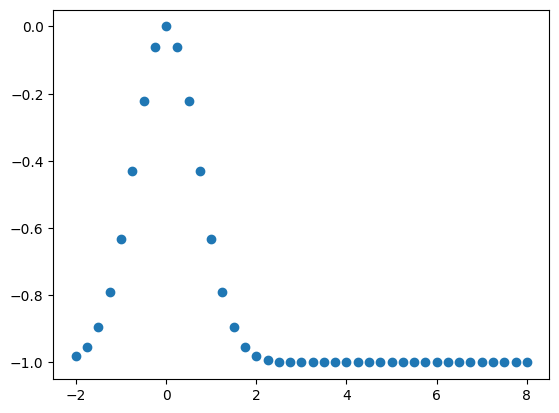

In [10]:
import PyMPDATA as pmp
import numpy as np
x = np.linspace(-2,8,41)
y = (np.exp(-x*x)-1)
import matplotlib.pyplot as plt
plt.scatter(x,y)
plt.show()

In [15]:
from PyMPDATA import ScalarField, VectorField,Options,Stepper,Solver,boundary_conditions
common = {
    'halo':(options := Options(nonoscillatory=True)).n_halo,
    'boundary_conditions':(boundary_conditions.Periodic(),)
}
advector = VectorField(**common,data = (np.full(x.size + 1, 0.25),))
advectee = ScalarField(**common, data = y)
stepper = Stepper(n_dims=1, options= options )
solver = Solver(advectee=advectee,advector=advector,stepper=stepper)
solver.advance(n_steps = 100)

5398.0

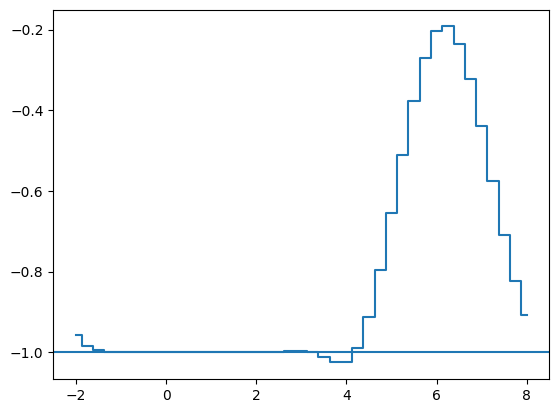

In [16]:
plt.step(x,solver.advectee.get(),where='mid')
plt.axhline(-1)
plt.show()